In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [48]:
df = pd.read_csv("Cars93_miss.csv")
df.head(3)

,Manufacturer,Model,Type,Min.Price,Price,Max.Price,MPG.city,MPG.highway,AirBags,DriveTrain,...,Passengers,Length,Wheelbase,Width,Turn.circle,Rear.seat.room,Luggage.room,Weight,Origin,Make
0,Acura,Integra,Small,12.9,15.9,18.8,25.0,31.0,NaN,Front,...,5.0,177.0,102.0,68.0,37.0,26.5,NaN,2705.0,non-USA,Acura Integra
1,NaN,Legend,Midsize,29.2,33.9,38.7,18.0,25.0,Driver & Passenger,Front,...,5.0,195.0,115.0,71.0,38.0,30.0,15.0,3560.0,non-USA,Acura Legend
2,Audi,90,Compact,25.9,29.1,32.3,20.0,26.0,Driver only,Front,...,5.0,180.0,102.0,67.0,37.0,28.0,14.0,3375.0,non-USA,Audi 90


In [49]:
df.shape

(93, 27)

In [50]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 93 entries, 0 to 92
Data columns (total 27 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Manufacturer        89 non-null     str    
 1   Model               92 non-null     str    
 2   Type                90 non-null     str    
 3   Min.Price           86 non-null     float64
 4   Price               91 non-null     float64
 5   Max.Price           88 non-null     float64
 6   MPG.city            84 non-null     float64
 7   MPG.highway         91 non-null     float64
 8   AirBags             55 non-null     str    
 9   DriveTrain          86 non-null     str    
 10  Cylinders           88 non-null     str    
 11  EngineSize          91 non-null     float64
 12  Horsepower          86 non-null     float64
 13  RPM                 90 non-null     float64
 14  Rev.per.mile        87 non-null     float64
 15  Man.trans.avail     88 non-null     str    
 16  Fuel.tank.capacity  8

In [51]:
df.describe()

,Min.Price,Price,Max.Price,MPG.city,MPG.highway,EngineSize,Horsepower,RPM,Rev.per.mile,Fuel.tank.capacity,Passengers,Length,Wheelbase,Width,Turn.circle,Rear.seat.room,Luggage.room,Weight
count,86.000000,91.000000,88.000000,84.000000,91.000000,91.000000,86.000000,90.000000,87.000000,85.000000,91.000000,89.000000,92.000000,87.000000,88.000000,89.000000,74.000000,86.000000
mean,17.118605,19.616484,21.459091,22.404762,29.065934,2.658242,144.000000,5276.666667,2355.000000,16.683529,5.076923,182.865169,103.956522,69.448276,38.954545,27.853933,13.986486,3104.593023
std,8.828290,9.724280,10.696563,5.841520,5.370293,1.045845,53.455204,605.554811,486.916616,3.375748,1.045953,14.792651,6.856317,3.778023,3.304157,3.018129,3.120824,600.129993
min,6.700000,7.400000,7.900000,15.000000,20.000000,1.000000,55.000000,3800.000000,1320.000000,9.200000,2.000000,141.000000,90.000000,60.000000,32.000000,19.000000,6.000000,1695.000000
25%,10.825000,12.350000,14.575000,18.000000,26.000000,1.800000,100.750000,4800.000000,2017.500000,14.500000,4.000000,174.000000,98.000000,67.000000,36.000000,26.000000,12.000000,2647.500000
50%,14.600000,17.700000,19.150000,21.000000,28.000000,2.300000,140.000000,5200.000000,2360.000000,16.500000,5.000000,181.000000,103.000000,69.000000,39.000000,27.500000,14.000000,3085.000000
75%,20.250000,23.500000,24.825000,25.000000,31.000000,3.250000,170.000000,5787.500000,2565.000000,19.000000,6.000000,192.000000,110.000000,72.000000,42.000000,30.000000,16.000000,3567.500000
max,45.400000,61.900000,80.000000,46.000000,50.000000,5.700000,300.000000,6500.000000,3755.000000,27.000000,8.000000,219.000000,119.000000,78.000000,45.000000,36.000000,22.000000,4105.000000


In [52]:
df.isnull().sum()

Manufacturer           4
Model                  1
Type                   3
Min.Price              7
Price                  2
Max.Price              5
MPG.city               9
MPG.highway            2
AirBags               38
DriveTrain             7
Cylinders              5
EngineSize             2
Horsepower             7
RPM                    3
Rev.per.mile           6
Man.trans.avail        5
Fuel.tank.capacity     8
Passengers             2
Length                 4
Wheelbase              1
Width                  6
Turn.circle            5
Rear.seat.room         4
Luggage.room          19
Weight                 7
Origin                 5
Make                   3
dtype: int64

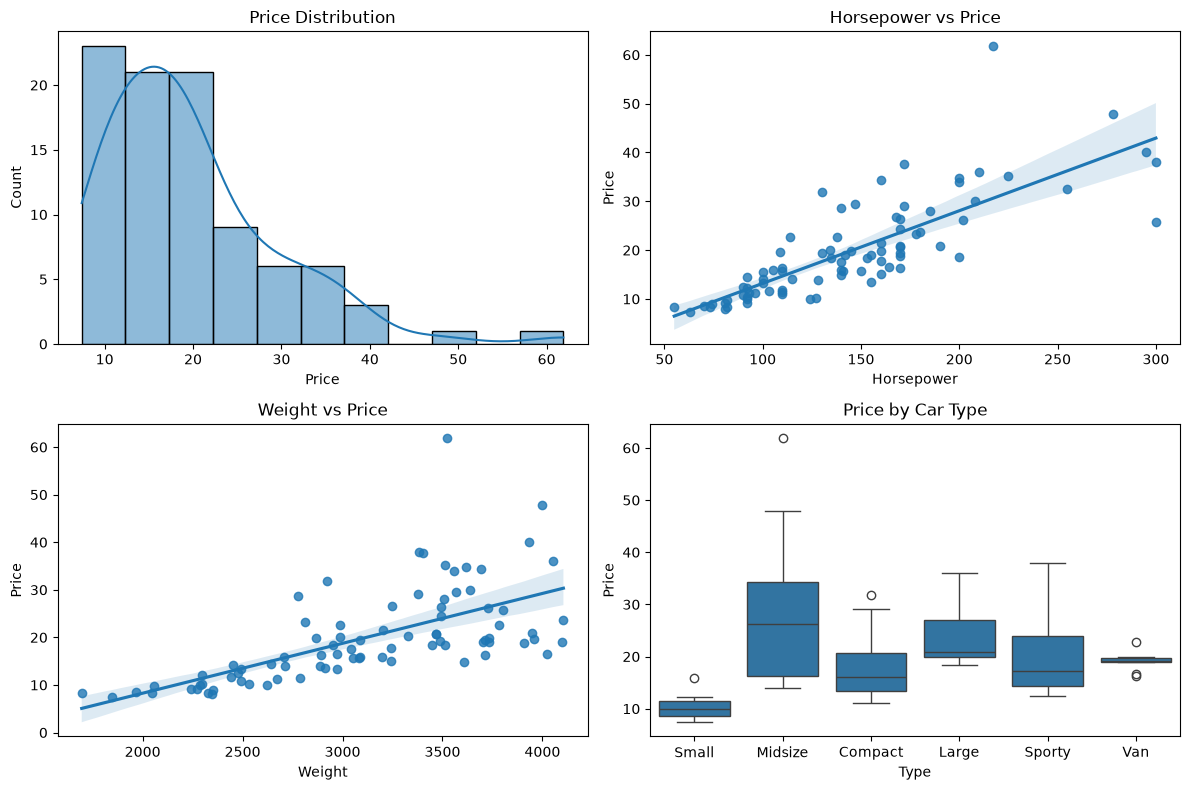

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df['Price'], kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Price Distribution')

sns.regplot(x='Horsepower', y='Price', data=df, ax=axes[0, 1])
axes[0, 1].set_title('Horsepower vs Price')

sns.regplot(x='Weight', y='Price', data=df, ax=axes[1, 0])
axes[1, 0].set_title('Weight vs Price')

sns.boxplot(x='Type', y='Price', data=df, ax=axes[1, 1])
axes[1, 1].set_title('Price by Car Type')

plt.tight_layout()
plt.show()

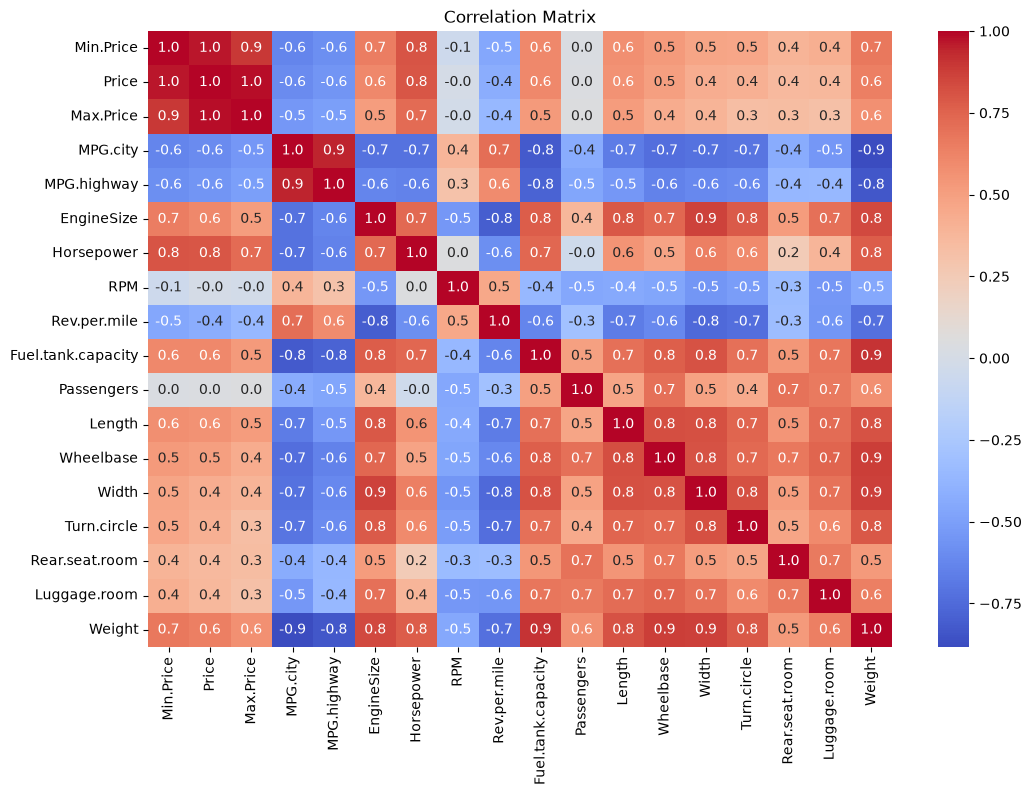

In [ ]:
plt.figure(figsize=(12,8))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, fmt='.1f', cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [ ]:
df = df.drop(['Manufacturer', 'Model', 'Make', 'Min.Price', 'Max.Price'], axis=1)
df = df.dropna(subset=['Price'])
df['Cylinders'] = pd.to_numeric(df['Cylinders'], errors='coerce')
df.shape

(91, 22)

In [ ]:
for col in df.select_dtypes(include='number').columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(exclude='number').columns:
    df[col] = df[col].fillna(df[col].mode()[0])

df.isnull().sum().sum()

np.int64(0)

In [57]:
df = pd.get_dummies(df, drop_first=True)
df.head()

,Price,MPG.city,MPG.highway,Cylinders,EngineSize,Horsepower,RPM,Rev.per.mile,Fuel.tank.capacity,Passengers,...,Type_Large,Type_Midsize,Type_Small,Type_Sporty,Type_Van,AirBags_Driver only,DriveTrain_Front,DriveTrain_Rear,Man.trans.avail_Yes,Origin_non-USA
0,15.9,25.0,31.0,4.0,1.8,140.0,6300.0,2890.0,13.2,5.0,...,False,False,True,False,False,True,True,False,True,True
1,33.9,18.0,25.0,6.0,3.2,200.0,5500.0,2335.0,18.0,5.0,...,False,True,False,False,False,False,True,False,True,True
2,29.1,20.0,26.0,6.0,2.8,172.0,5500.0,2280.0,16.9,5.0,...,False,False,False,False,False,True,True,False,True,True
3,37.7,19.0,26.0,6.0,2.4,172.0,5500.0,2535.0,21.1,6.0,...,False,True,False,False,False,False,True,False,True,True
4,30.0,22.0,30.0,4.0,3.5,208.0,5700.0,2545.0,21.1,4.0,...,False,True,False,False,False,True,False,True,True,True


In [ ]:
X = df.drop('Price', axis=1)
y = df['Price']

x_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
x_train.shape, X_test.shape

((72, 26), (19, 26))

In [ ]:
model = LinearRegression()
model.fit(x_train, y_train)

y_train_pred = model.predict(x_train)
y_test_pred = model.predict(X_test)

In [ ]:
print('Intercept (B0):', model.intercept_)
coef = pd.Series(model.coef_, index=X.columns).sort_values()
coef

Intercept (B0): 73.45188151631368


AirBags_Driver only   -4.862182
Man.trans.avail_Yes   -3.371948
Type_Small            -2.305983
Width                 -1.423625
MPG.city              -0.449727
Turn.circle           -0.273413
Length                -0.130855
Fuel.tank.capacity    -0.006858
Weight                -0.000253
RPM                   -0.000111
Rev.per.mile           0.004904
MPG.highway            0.027578
Horsepower             0.103563
Wheelbase              0.247263
Type_Large             0.256322
Type_Van               0.315113
Luggage.room           0.368212
Rear.seat.room         0.553884
EngineSize             0.638822
DriveTrain_Front       1.368806
Passengers             1.382804
Cylinders              1.972301
Type_Midsize           3.302189
Origin_non-USA         4.179949
Type_Sporty            7.173400
DriveTrain_Rear        8.419655
dtype: float64

In [65]:
def evaluate(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return [mae, mse, rmse, r2]

metrics = ['MAE', 'MSE', 'RMSE', 'R2']

results = {
    'Train': dict(zip(metrics, evaluate(y_train, y_train_pred))),
    'Test': dict(zip(metrics, evaluate(y_test, y_test_pred)))
}
results

{'Train': {'MAE': 2.9759540627224923,
  'MSE': 15.029914327691037,
  'RMSE': np.float64(3.876843345776437),
  'R2': 0.8413963364701327},
 'Test': {'MAE': 3.9131100270172112,
  'MSE': 26.058632570915435,
  'RMSE': np.float64(5.104765672478555),
  'R2': 0.7032703602360777}}

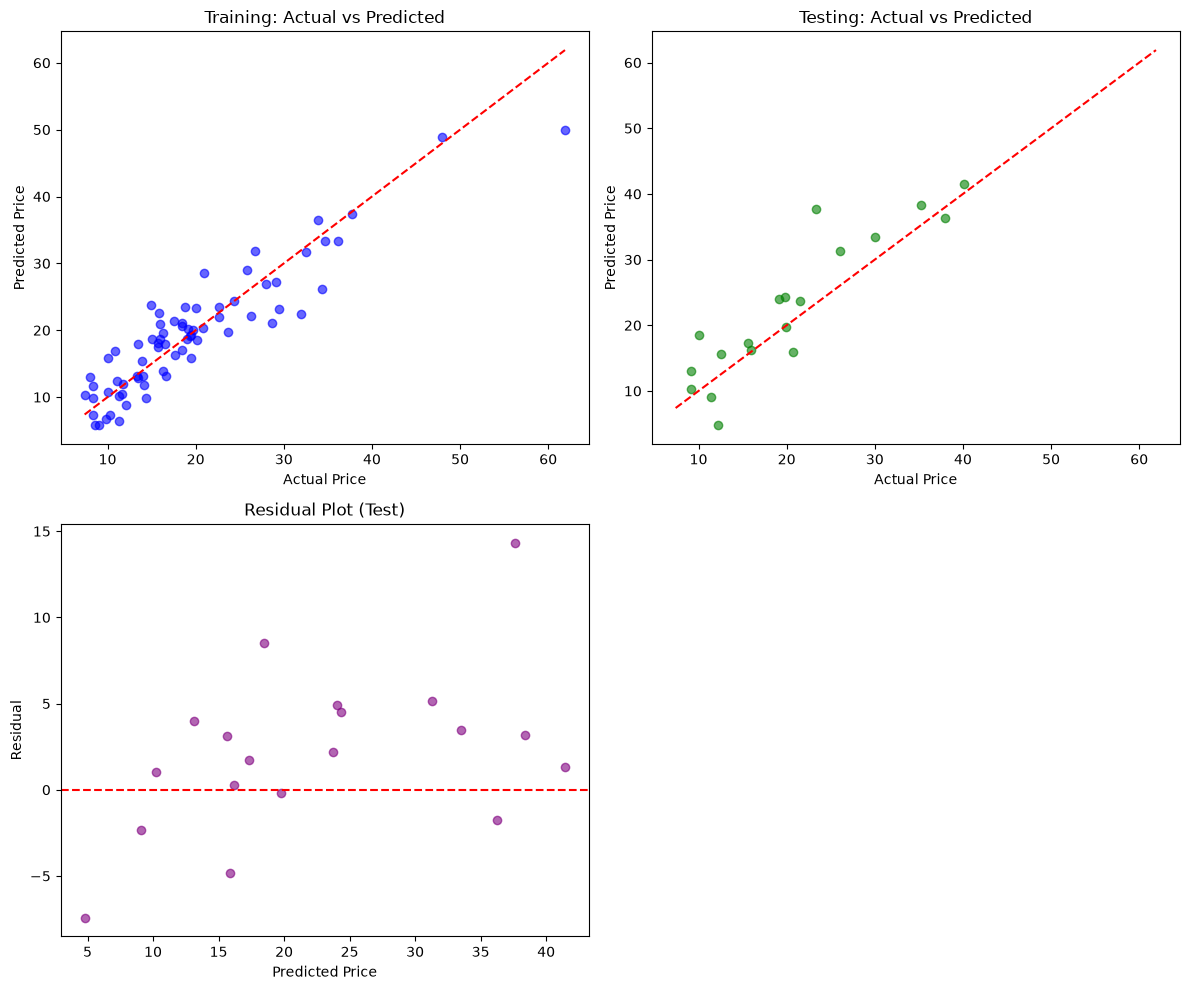

In [68]:
residuals_test = y_test_pred - y_test
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].scatter(y_train, y_train_pred, color='blue', alpha=0.6)
axes[0, 0].plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--')
axes[0, 0].set_xlabel('Actual Price')
axes[0, 0].set_ylabel('Predicted Price')
axes[0, 0].set_title('Training: Actual vs Predicted')

axes[0, 1].scatter(y_test, y_test_pred, color='green', alpha=0.6)
axes[0, 1].plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--')
axes[0, 1].set_xlabel('Actual Price')
axes[0, 1].set_ylabel('Predicted Price')
axes[0, 1].set_title('Testing: Actual vs Predicted')

axes[1, 0].scatter(y_test_pred, residuals_test, color='purple', alpha=0.6)
axes[1, 0].axhline(0, color='red', linestyle='--')
axes[1, 0].set_xlabel('Predicted Price')
axes[1, 0].set_ylabel('Residual')
axes[1, 0].set_title('Residual Plot (Test)')

fig.delaxes(axes[1, 1])

plt.tight_layout()
plt.show()